In [10]:
# Intalar librerias
if (!requireNamespace("arules"))
  install.packages("arules")

In [11]:
#install.packages(c("arulesViz", "tidyr", "dplyr", "ggplot2", "readr"))
if (!requireNamespace("arulesViz"))
    install.packages("arulesViz")
if (!requireNamespace("tidyr"))
    install.packages("tidyr")
if (!requireNamespace("dplyr"))
    install.packages("dplyr")
if (!requireNamespace("ggplot2"))
    install.packages("ggplot2")
if (!requireNamespace("readr"))
    install.packages("readr")

In [12]:
#
# CARGA LIBRERIA Y DATOS
# --------------------------------------------------------------
library(arules)
library(arulesViz);
library(ggplot2)
library(tidyr)
library(dplyr)

In [13]:
library(readr)
# Arrastramos el fichero Groceries.csv la carpeta Archivos
# Usamos read_csv2 si el archivo usa ';' como delimitador
datos_retail <- read_csv2("OnlineRetail_5.csv")

# TRANSFORMA Data.Frame en TRANSACCIONAL
# --------------------------------------------------------------
# Transforma  data.frame en transaccional
trx       <- datos_retail
trx       <- split(trx$Description, trx$InvoiceNo) # convierte datos en lista
trx       <- as(trx, "transactions")               # convierte datos en transacciones

ℹ Using "','" as decimal and "'.'" as grouping mark. Use `read_delim()` for more control.

Rows: 39224 Columns: 2
── Column specification ────────────────────────────────────────────────────────
Delimiter: ";"
chr (2): InvoiceNo, Description

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message in asMethod(object):
“removing duplicated items in transactions”


In [16]:
# 1. Cálculo del Gasto Promedio por Transacción (Ticket Promedio):
items_por_factura <- size(trx)
cat("Número de facturas:", length(trx), "\n")
cat("Ticket promedio (ítems por factura):", round(mean(items_por_factura), 2), "\n")

Número de facturas: 2259 
Ticket promedio (ítems por factura): 17.07 


In [19]:
# 2. Frecuencia Porcentual
FreqPorc <- data.frame(Producto = names(itemFrequency(trx)),
                       Frecuencia = round(itemFrequency(trx, type = "relative") * 100, 2),
                       row.names = NULL)
FreqPorc <- FreqPorc[order(FreqPorc$Frecuencia, decreasing = T), ] # Ordena de mas a menos frecuencia
head(FreqPorc, 20) # Muestra los 20 primeros, porque si no serian demasiados

,Producto,Frecuencia
,<chr>,<dbl>
1603,PARTY BUNTING,11.42
2279,SPOTTY BUNTING,9.87
1185,JUMBO BAG RED RETROSPOT,9.16
1179,JUMBO BAG DOILEY PATTERNS,8.28
2516,WHITE HANGING HEART T-LIGHT HOLDER,8.23
1876,REGENCY CAKESTAND 3 TIER,8.15
1309,LUNCH BAG APPLE DESIGN,7.44
1311,LUNCH BAG DOILEY PATTERN,7.26
1314,LUNCH BAG RED RETROSPOT,6.91


In [32]:
# CREA REGLAS
# --------------------------------------------------------------
reglas <- apriori(trx, parameter=list(support=0.01, confidence = 0.01))

Apriori

Parameter specification:
 confidence minval smax arem  aval originalSupport maxtime support minlen
       0.01    0.1    1 none FALSE            TRUE       5    0.01      1
 maxlen target  ext
     10  rules TRUE

Algorithmic control:
 filter tree heap memopt load sort verbose
    0.1 TRUE TRUE  FALSE TRUE    2    TRUE

Absolute minimum support count: 22 

set item appearances ...[0 item(s)] done [0.00s].
set transactions ...[2626 item(s), 2259 transaction(s)] done [0.01s].
sorting and recoding items ... [498 item(s)] done [0.00s].
creating transaction tree ... done [0.00s].
checking subsets of size 1 2 3 4 5 6 done [0.01s].
writing ... [4330 rule(s)] done [0.00s].
creating S4 object  ... done [0.00s].


In [33]:
# 3. Reglas con Alto Lift
reglas <- sort(reglas, by = "lift", decreasing = TRUE)
inspect(head(reglas, 10))

     lhs                             rhs                             support confidence   coverage     lift count
[1]  {SET/6 COLLAGE PAPER CUPS}   => {SET/6 COLLAGE PAPER PLATES} 0.01328021  1.0000000 0.01328021 66.44118    30
[2]  {SET/6 COLLAGE PAPER PLATES} => {SET/6 COLLAGE PAPER CUPS}   0.01328021  0.8823529 0.01505091 66.44118    30
[3]  {HERB MARKER MINT,                                                                                          
      HERB MARKER PARSLEY,                                                                                       
      HERB MARKER ROSEMARY,                                                                                      
      HERB MARKER THYME}          => {HERB MARKER CHIVES}         0.01328021  0.9375000 0.01416556 60.50893    30
[4]  {HERB MARKER BASIL,                                                                                         
      HERB MARKER MINT,                                                                 

In [36]:
# 4. Toma de Decisión Logística (Basado en Confianza y Lift):
#   a) Indique los 3 productos
umbral_confianza <- 0.80 # Porque todas las reglas tiene un valor lift mayor que 0.5
umbral_lift      <- 10   # Media del lift ~10.7

reglas_estante <- subset(reglas, confidence > umbral_confianza & lift > umbral_lift)
reglas_estante <- reglas_estante[size(reglas_estante) == 3]
reglas_estante <- sort(reglas_estante, by = "support", decreasing = TRUE)
inspect(head(reglas_estante, 5))

as(items(reglas_estante[1]), "list")[[1]]

    lhs                            rhs                           support confidence   coverage     lift count
[1] {REGENCY SUGAR BOWL GREEN,                                                                               
     REGENCY TEAPOT ROSES}      => {REGENCY MILK JUG PINK}    0.03010181  0.9315068 0.03231518 23.64353    68
[2] {REGENCY MILK JUG PINK,                                                                                  
     REGENCY TEAPOT ROSES}      => {REGENCY SUGAR BOWL GREEN} 0.03010181  0.9444444 0.03187251 22.45789    68
[3] {REGENCY MILK JUG PINK,                                                                                  
     REGENCY SUGAR BOWL GREEN}  => {REGENCY TEAPOT ROSES}     0.03010181  0.8947368 0.03364320 19.62340    68
[4] {REGENCY TEA PLATE PINK,                                                                                 
     REGENCY TEA PLATE ROSES}   => {REGENCY TEA PLATE GREEN}  0.02788845  0.9843750 0.02833112 26.79160    63
[5] {REGEN

[1] "REGENCY MILK JUG PINK"    "REGENCY SUGAR BOWL GREEN"
[3] "REGENCY TEAPOT ROSES"

In [38]:
#   b) Indique los 5 productos
head(FreqPorc, 5)

,Producto,Frecuencia
,<chr>,<dbl>
1603,PARTY BUNTING,11.42
2279,SPOTTY BUNTING,9.87
1185,JUMBO BAG RED RETROSPOT,9.16
1179,JUMBO BAG DOILEY PATTERNS,8.28
2516,WHITE HANGING HEART T-LIGHT HOLDER,8.23


In [29]:
# PRINT
# --------------------------------------------------------------
# cantidad de reglas creadas
print(reglas)
# imprime todas las reglas
inspect(reglas)

Se han truncado las últimas 5000 líneas del flujo de salida.
        JUMBO BAG TOYS,                                                                                                                
        JUMBO BAG WOODLAND ANIMALS}           => {JUMBO STORAGE BAG SUKI}              0.01283754 0.87878788 0.01460823 16.009531    29
[1059] {DOTCOM POSTAGE,                                                                                                                
        JUMBO BAG RED RETROSPOT,                                                                                                       
        JUMBO BAG TOYS}                       => {JUMBO STORAGE BAG SUKI}              0.01283754 0.87878788 0.01460823 16.009531    29
[1060] {DOTCOM POSTAGE,                                                                                                                
        JUMBO BAG PINK POLKADOT,                                                                                           

In [ ]:
# data.frame con frecuencia porcentual de cada producto
FreqProd <- data.frame(Producto=names(itemFrequency(trx)),
                       Frecuencia=itemFrequency(trx), row.names=NULL)
FreqProd <- FreqProd[order(FreqProd$Frecuencia, decreasing = T),]
FreqProd

In [ ]:
#Print del data set de transacciones
inspect(trx)

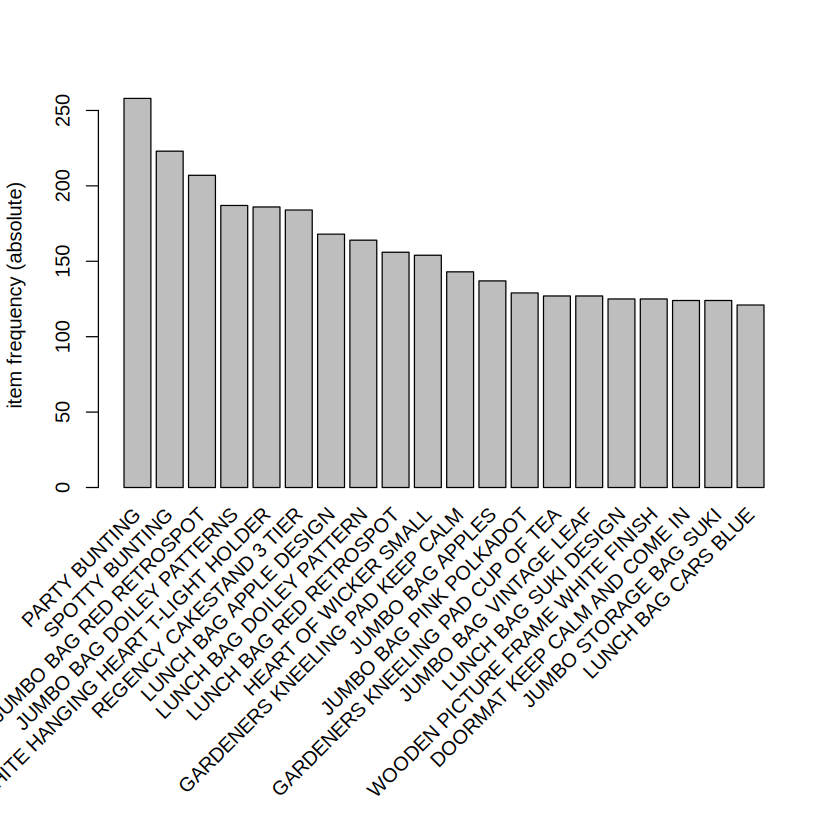

In [30]:
# PLOT
# --------------------------------------------------------------
reglas <-sort(reglas, by="confidence", decreasing=TRUE) # ordena reglas

# grafica los 20 productos mas frecuente
itemFrequencyPlot(trx,topN=20,type="absolute")

In [31]:
# imprime las 3 reglas con mayor confianza
reglas <-sort(reglas, by="confidence", decreasing=TRUE) # ordena regla
inspect(head(reglas,3))

    lhs                           rhs                             support confidence   coverage     lift count
[1] {SET/6 COLLAGE PAPER CUPS} => {SET/6 COLLAGE PAPER PLATES} 0.01328021          1 0.01328021 66.44118    30
[2] {HERB MARKER CHIVES,                                                                                      
     HERB MARKER MINT}         => {HERB MARKER PARSLEY}        0.01460823          1 0.01460823 56.47500    33
[3] {HERB MARKER CHIVES,                                                                                      
     HERB MARKER MINT,                                                                                        
     HERB MARKER ROSEMARY}     => {HERB MARKER PARSLEY}        0.01372289          1 0.01372289 56.47500    31


In [ ]:
# Grafico de red 20 reglas con mayor confianza
plot(head(reglas,20), method="graph")

In [ ]:
# Grafico de matriz de 100 regla con mayor confianza
plot(head(reglas,100), method="grouped")


In [ ]:
# grafico de dispersion de todas las reglas
plot(reglas)